# Homogeneous-region distributions

In [1]:
from pathlib import Path
import sys
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/random.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from gw import supporting_reports as report
from gw.classification_report import show
import matplotlib.pyplot as plt
from gw.publication_ui import folded_table, folded_comparison, compact_settings

## Results

Five fit/evaluation splits · average held-out NLL and KS.

In [2]:
table=report.fit(ROOT)
show(table,{'NLL ↓':'{:.4f}','KS ↓':'{:.4f}'})

## Fit comparison

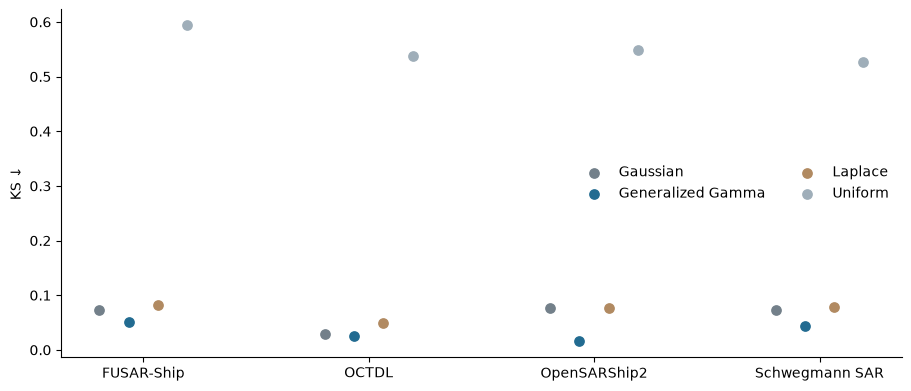

In [3]:
figure=report.fit_plot(table,ROOT/'assets/figures/distribution_fit.png')
display(figure)
plt.close(figure)

<details><summary>Distribution model</summary>

The fitted model is generalized Gamma, labelled Gamma in the manuscript table.

</details>

## Regions

Saved training-image region checks. Set `RUN_SELECTION = True` to rebuild the blocks.

In [4]:
from gw import region_selection, region_report
RUN_SELECTION = False
SOURCE_DIRS = {}  # Optional dataset → prepared-image directory
region_runs = {key: ROOT/'results/fit/regions'/key for key in ['opensar','sar','fusar','oct']}
if RUN_SELECTION:
    region_runs = {key: region_selection.run(ROOT,key,source_dir=SOURCE_DIRS.get(key)) for key in region_runs}
show(region_report.summary(ROOT,region_runs).drop(columns=['Matches']))

,Train images,Blocks,Groups
Dataset,,,
OpenSARShip2,4396,157,11
Schwegmann SAR,6642,99,13
FUSAR-Ship,188,166,161
OCTDL,1477,543,543


## Refit

Fixed blocks · positive pixel/block-mean samples · five 70/30 group splits.

Saved new fits are shown below. Set `RUN_REFIT = True` to fit the same blocks again.

In [5]:
from gw import distribution_fitting as fitting
RUN_REFIT = False
directory = fitting.run(ROOT,region_runs=region_runs) if RUN_REFIT else ROOT/'results/fit/refit'
comparison = fitting.paper_comparison(ROOT,directory)
view=comparison[['Coordinate','NLL ↓','KS ↓']].copy()
view['Coordinate']=view['Coordinate'].replace({'model_gray':'Scaled pixels','stored':'Stored pixels'})
folded_table('Refit results', view)

## Settings

In [6]:
from IPython.display import HTML
settings=fitting.input_settings(ROOT)
display(HTML('<details><summary>Fit settings</summary>'+settings.to_html(border=0)+'</details>'))

,Blocks,Groups,Pixels
Dataset,,,
OpenSARShip2,157,11,Scaled
Schwegmann SAR,99,13,Scaled
FUSAR-Ship,166,161,Scaled / Stored
OCTDL,543,543,Scaled
